
# پیش‌بینی ۷۲ ساعت آینده PM10 در ایستگاه Gucheng با RNN، LSTM و GRU

این نوت‌بوک یک نسخه‌ی پژوهشی و اصلاح‌شده از الگوی اولیه‌ی GitHub است و برای دیتاست `Gucheng.csv` بازطراحی شده است.

## طراحی آزمایش

- **مسئله:** پیش‌بینی غلظت `PM10` دقیقاً ۷۲ ساعت بعد
- **نوع مسئله:** Multivariate Time-Series Forecasting (بدون مدل‌سازی مکانی)
- **Look-back پیش‌فرض:** 24 ساعت گذشته
- **Forecast horizon پیش‌فرض:** 72 ساعت آینده
- **تقسیم زمانی:** 70٪ آموزش، 15٪ اعتبارسنجی، 15٪ آزمون
- **مدل‌ها:** SimpleRNN، LSTM، GRU
- **Baseline:** Persistence (مقدار PM10 در آخرین ساعت مشاهده‌شده به‌عنوان پیش‌بینی PM10 دقیقاً ۷۲ ساعت بعد)
- **معیارها:** MAE، RMSE، R² و sMAPE در مقیاس واقعی `µg/m³`

## اصلاحات روش‌شناختی نسبت به نوت‌بوک اولیه

1. هدف در زمان آینده قرار گرفته است؛ مقدار هدف دیگر داخل پنجره‌ی ورودی نیست.
2. شکل ورودی شبکه به‌صورت صحیح `(samples, time_steps, features)` نگه داشته می‌شود.
3. scaler فقط روی بخش آموزش برازش می‌شود.
4. Validation و Test به‌ترتیب زمانی و بدون shuffle ساخته می‌شوند.
5. معیارهای نهایی بعد از inverse-transform و در واحد واقعی PM10 محاسبه می‌شوند.
6. هر سه معماری با عمق، تعداد واحدها، dropout، optimizer و پروتکل آموزش یکسان مقایسه می‌شوند.
7. برای ارزیابی واقع‌بینانه، یک Persistence baseline نیز گزارش می‌شود.



## 1. نصب کتابخانه‌ها

اگر محیط شما TensorFlow ندارد، خط زیر را یک بار اجرا کنید.


In [1]:
# Optional installation (uncomment if needed)
!pip install -q tensorflow scikit-learn pandas matplotlib joblib

## 2. کتابخانه‌ها و تنظیمات بازتولیدپذیری

In [2]:
import os
import json
import time
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense, Dropout, SimpleRNN, LSTM, GRU
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

# ---------------------------
# Experiment configuration
# ---------------------------
DATA_PATH = Path("Gucheng.csv")
TARGET = "PM10"

LOOKBACK = 24       # previous 24 hourly observations
HORIZON = 72        # predict exactly 72 hours ahead
TRAIN_RATIO = 0.70
VAL_RATIO = 0.15
TEST_RATIO = 0.15

EPOCHS = 100
BATCH_SIZE = 64
LEARNING_RATE = 4e-4
DROPOUT = 0.20
PATIENCE = 10

assert abs(TRAIN_RATIO + VAL_RATIO + TEST_RATIO - 1.0) < 1e-9

print("TensorFlow:", tf.__version__)
print("Data path:", DATA_PATH.resolve())

TensorFlow: 2.20.0
Data path: /content/Gucheng.csv



## 3. بارگذاری داده و ساخت محور زمانی

فایل Gucheng دارای ستون‌های `year`, `month`, `day`, `hour` است. آن‌ها به یک ستون `datetime` تبدیل می‌شوند و داده بر اساس زمان مرتب می‌شود.


In [3]:
from google.colab import files
uploaded = files.upload()

Saving Gucheng.csv to Gucheng.csv


In [4]:
df_raw = pd.read_csv('Gucheng.csv')

required_columns = [
    "year", "month", "day", "hour",
    "PM2.5", "PM10", "SO2", "NO2", "CO", "O3",
    "TEMP", "PRES", "DEWP", "RAIN", "wd", "WSPM"
]

missing_required = [c for c in required_columns if c not in df_raw.columns]
if missing_required:
    raise ValueError(f"Missing required columns: {missing_required}")

df = df_raw.copy()
df["datetime"] = pd.to_datetime(df[["year", "month", "day", "hour"]])
df = df.sort_values("datetime").reset_index(drop=True)

print("Shape:", df.shape)
print("Time range:", df["datetime"].min(), "to", df["datetime"].max())
display(df.head())

Shape: (35064, 19)
Time range: 2013-03-01 00:00:00 to 2017-02-28 23:00:00


,No,year,month,day,hour,PM2.5,PM10,SO2,NO2,CO,O3,TEMP,PRES,DEWP,RAIN,wd,WSPM,station,datetime
0,1,2013,3,1,0,6.0,18.0,5.0,NaN,800.0,88.0,0.1,1021.1,-18.6,0.0,NW,4.4,Gucheng,2013-03-01 00:00:00
1,2,2013,3,1,1,6.0,15.0,5.0,NaN,800.0,88.0,-0.3,1021.5,-19.0,0.0,NW,4.0,Gucheng,2013-03-01 01:00:00
2,3,2013,3,1,2,5.0,18.0,NaN,NaN,700.0,52.0,-0.7,1021.5,-19.8,0.0,WNW,4.6,Gucheng,2013-03-01 02:00:00
3,4,2013,3,1,3,6.0,20.0,6.0,NaN,NaN,NaN,-1.0,1022.7,-21.2,0.0,W,2.8,Gucheng,2013-03-01 03:00:00
4,5,2013,3,1,4,5.0,17.0,5.0,NaN,600.0,73.0,-1.3,1023.0,-21.4,0.0,WNW,3.6,Gucheng,2013-03-01 04:00:00


## 4. کنترل کیفیت اولیه‌ی سری زمانی

In [5]:
# Check duplicates and time continuity
duplicate_times = df["datetime"].duplicated().sum()
time_diffs = df["datetime"].diff().dropna()
irregular_steps = (time_diffs != pd.Timedelta(hours=1)).sum()

print("Duplicate timestamps:", duplicate_times)
print("Irregular (non-hourly) time steps:", irregular_steps)

missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (100 * df.isna().mean()).round(3)
}).sort_values("missing_percent", ascending=False)

display(missing_summary[missing_summary["missing_count"] > 0])

if duplicate_times > 0:
    raise ValueError("Duplicate timestamps detected. Resolve them before modeling.")
if irregular_steps > 0:
    print("WARNING: The time series is not perfectly hourly. Consider reindexing before modeling.")

Duplicate timestamps: 0
Irregular (non-hourly) time steps: 0


,missing_count,missing_percent
CO,1401,3.996
O3,729,2.079
NO2,668,1.905
PM2.5,646,1.842
SO2,507,1.446
PM10,381,1.087
wd,159,0.453
DEWP,51,0.145
TEMP,51,0.145
PRES,50,0.143


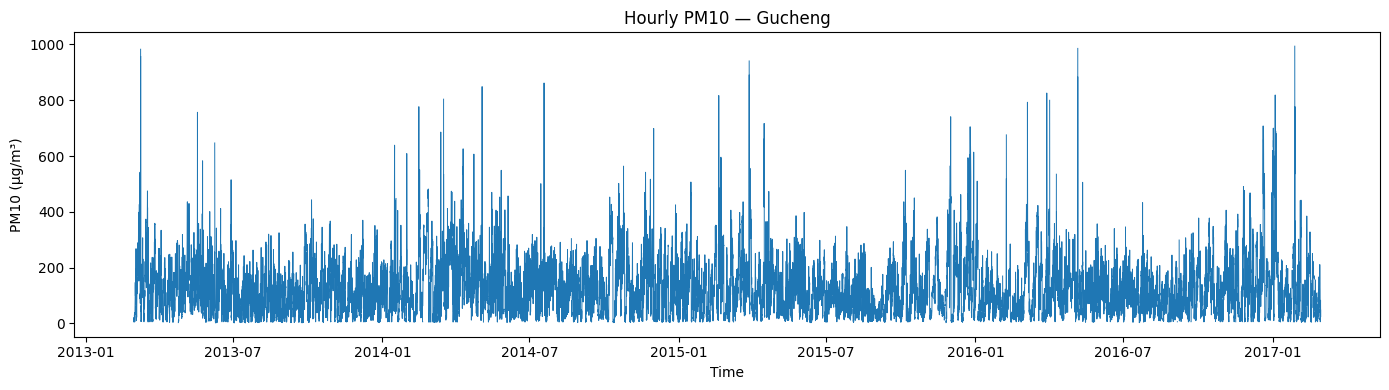

In [6]:
plt.figure(figsize=(14, 4))
plt.plot(df["datetime"], df["PM10"], linewidth=0.7)
plt.title("Hourly PM10 — Gucheng")
plt.xlabel("Time")
plt.ylabel("PM10 (µg/m³)")
plt.tight_layout()
plt.show()


## 5. تعیین مرزهای Train / Validation / Test

مرزها **قبل از هر نوع scaling** تعیین می‌شوند.  
تمام مراحل وابسته به توزیع داده (مثل محاسبه‌ی median و scaler) فقط از بخش Train یاد می‌گیرند.


In [7]:
n = len(df)
train_end = int(n * TRAIN_RATIO)
val_end = int(n * (TRAIN_RATIO + VAL_RATIO))

print("Total rows:", n)
print("Train rows:", train_end)
print("Validation rows:", val_end - train_end)
print("Test rows:", n - val_end)

print("\nTrain:", df.loc[0, "datetime"], "→", df.loc[train_end - 1, "datetime"])
print("Validation:", df.loc[train_end, "datetime"], "→", df.loc[val_end - 1, "datetime"])
print("Test:", df.loc[val_end, "datetime"], "→", df.loc[n - 1, "datetime"])

Total rows: 35064
Train rows: 24544
Validation rows: 5260
Test rows: 5260

Train: 2013-03-01 00:00:00 → 2015-12-18 15:00:00
Validation: 2015-12-18 16:00:00 → 2016-07-24 19:00:00
Test: 2016-07-24 20:00:00 → 2017-02-28 23:00:00



## 6. مدیریت مقادیر گمشده بدون نشت اطلاعات

برای جلوگیری از استفاده از آینده:

- ابتدا از **forward fill** استفاده می‌شود؛ این روش فقط از گذشته استفاده می‌کند.
- اگر در ابتدای سری هنوز مقدار گمشده باقی بماند، برای متغیرهای عددی از **median بخش Train** استفاده می‌شود.
- برای جهت باد از **mode بخش Train** استفاده می‌شود.

> از interpolation دوطرفه یا مدل‌هایی که کل دیتاست را هم‌زمان برای پرکردن missing می‌بینند استفاده نشده است.


In [8]:
numeric_measure_cols = [
    "PM2.5", "PM10", "SO2", "NO2", "CO", "O3",
    "TEMP", "PRES", "DEWP", "RAIN", "WSPM"
]

train_medians = df.loc[:train_end - 1, numeric_measure_cols].median()
train_wd_mode = df.loc[:train_end - 1, "wd"].mode(dropna=True)
train_wd_mode = train_wd_mode.iloc[0] if len(train_wd_mode) else "N"

# Causal imputation
df[numeric_measure_cols] = df[numeric_measure_cols].ffill()
df["wd"] = df["wd"].ffill()

# Handle any values still missing at the beginning of the series
df[numeric_measure_cols] = df[numeric_measure_cols].fillna(train_medians)
df["wd"] = df["wd"].fillna(train_wd_mode)

print("Remaining missing values in modeling columns:",
      int(df[numeric_measure_cols + ["wd"]].isna().sum().sum()))

Remaining missing values in modeling columns: 0



## 7. مهندسی ویژگی‌های زمانی و جهت باد

برای متغیرهای چرخه‌ای از کدگذاری سینوس/کسینوس استفاده می‌شود تا نزدیکی طبیعی نقاط انتهایی چرخه حفظ شود؛ برای مثال ساعت 23 و ساعت 0 باید نزدیک یکدیگر دیده شوند.

ویژگی‌های ساخته‌شده:

- `hour_sin`, `hour_cos`
- `month_sin`, `month_cos`
- `dow_sin`, `dow_cos`
- `wd_sin`, `wd_cos`

در مرحله‌ی پایه از نسبت‌های آلاینده‌ای مانند `NO2/PM2.5` استفاده نمی‌شود تا مقایسه‌ی معماری‌ها تا حد ممکن ساده و قابل تفسیر باقی بماند.


In [9]:
# Calendar features
df["dow"] = df["datetime"].dt.dayofweek

df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)

df["month_sin"] = np.sin(2 * np.pi * (df["month"] - 1) / 12)
df["month_cos"] = np.cos(2 * np.pi * (df["month"] - 1) / 12)

df["dow_sin"] = np.sin(2 * np.pi * df["dow"] / 7)
df["dow_cos"] = np.cos(2 * np.pi * df["dow"] / 7)

# 16-point compass → degrees
wind_degrees = {
    "N": 0.0, "NNE": 22.5, "NE": 45.0, "ENE": 67.5,
    "E": 90.0, "ESE": 112.5, "SE": 135.0, "SSE": 157.5,
    "S": 180.0, "SSW": 202.5, "SW": 225.0, "WSW": 247.5,
    "W": 270.0, "WNW": 292.5, "NW": 315.0, "NNW": 337.5
}

unknown_wd = sorted(set(df["wd"].dropna().unique()) - set(wind_degrees))
if unknown_wd:
    raise ValueError(f"Unknown wind-direction categories: {unknown_wd}")

wd_rad = np.deg2rad(df["wd"].map(wind_degrees).astype(float))
df["wd_sin"] = np.sin(wd_rad)
df["wd_cos"] = np.cos(wd_rad)

display(df[["datetime", "hour_sin", "hour_cos", "month_sin", "month_cos",
            "dow_sin", "dow_cos", "wd", "wd_sin", "wd_cos"]].head())

,datetime,hour_sin,hour_cos,month_sin,month_cos,dow_sin,dow_cos,wd,wd_sin,wd_cos
0,2013-03-01 00:00:00,0.000000,1.000000,0.866025,0.5,-0.433884,-0.900969,NW,-0.707107,7.071068e-01
1,2013-03-01 01:00:00,0.258819,0.965926,0.866025,0.5,-0.433884,-0.900969,NW,-0.707107,7.071068e-01
2,2013-03-01 02:00:00,0.500000,0.866025,0.866025,0.5,-0.433884,-0.900969,WNW,-0.923880,3.826834e-01
3,2013-03-01 03:00:00,0.707107,0.707107,0.866025,0.5,-0.433884,-0.900969,W,-1.000000,-1.836970e-16
4,2013-03-01 04:00:00,0.866025,0.500000,0.866025,0.5,-0.433884,-0.900969,WNW,-0.923880,3.826834e-01


## 8. انتخاب ویژگی‌ها

In [10]:
FEATURES = [
    # Pollutants
    "PM2.5", "PM10", "SO2", "NO2", "CO", "O3",
    # Meteorology
    "TEMP", "PRES", "DEWP", "RAIN", "WSPM",
    # Cyclical calendar features
    "hour_sin", "hour_cos",
    "month_sin", "month_cos",
    "dow_sin", "dow_cos",
    # Wind direction
    "wd_sin", "wd_cos"
]

print("Number of input features:", len(FEATURES))
print(FEATURES)

display(df[FEATURES + [TARGET]].describe().T)

Number of input features: 19
['PM2.5', 'PM10', 'SO2', 'NO2', 'CO', 'O3', 'TEMP', 'PRES', 'DEWP', 'RAIN', 'WSPM', 'hour_sin', 'hour_cos', 'month_sin', 'month_cos', 'dow_sin', 'dow_cos', 'wd_sin', 'wd_cos']


,count,mean,std,min,25%,50%,75%,max
PM2.5,35064.0,8.434520e+01,83.228885,2.000000,24.000000,6.000000e+01,116.000000,770.000000
PM10,35064.0,1.193290e+02,97.650791,2.000000,45.000000,1.000000e+02,167.000000,994.000000
SO2,35064.0,1.602008e+01,27.031552,0.285600,2.000000,7.000000e+00,20.000000,500.000000
NO2,35064.0,5.582096e+01,36.525063,2.000000,26.000000,5.000000e+01,79.000000,276.000000
CO,35064.0,1.352702e+03,1236.264470,100.000000,600.000000,9.000000e+02,1700.000000,10000.000000
O3,35064.0,5.870256e+01,58.243262,0.214200,10.000000,4.500000e+01,84.000000,450.000000
TEMP,35064.0,1.385569e+01,11.295553,-15.600000,3.600000,1.480000e+01,23.500000,41.600000
PRES,35064.0,1.008836e+03,10.104802,984.000000,1000.500000,1.008500e+03,1017.000000,1038.100000
DEWP,35064.0,2.600456e+00,13.789758,-34.600000,-9.000000,3.000000e+00,15.300000,27.400000
RAIN,35064.0,6.437372e-02,0.838142,0.000000,0.000000,0.000000e+00,0.000000,41.900000



## 9. Scaling فقط بر اساس Train

دو scaler جدا استفاده می‌شود:

- `feature_scaler` برای تمام ورودی‌ها
- `target_scaler` برای PM10 هدف

هر دو فقط روی داده‌ی Train برازش می‌شوند.


In [11]:
feature_scaler = StandardScaler()
target_scaler = StandardScaler()

feature_scaler.fit(df.loc[:train_end - 1, FEATURES])
target_scaler.fit(df.loc[:train_end - 1, [TARGET]])

X_all_scaled = feature_scaler.transform(df[FEATURES]).astype(np.float32)
y_all_scaled = target_scaler.transform(df[[TARGET]]).astype(np.float32).reshape(-1)

print("Scaled feature matrix:", X_all_scaled.shape)
print("Scaled target vector:", y_all_scaled.shape)

Scaled feature matrix: (35064, 19)
Scaled target vector: (35064,)



## 10. تبدیل سری زمانی به Sliding Windows

برای `LOOKBACK=24` و `HORIZON=72`:

- ورودی: 24 ساعت متوالی از گذشته، یعنی ساعت‌های `t-23` تا `t`
- هدف: `PM10` دقیقاً 72 ساعت بعد، یعنی در زمان `t+72`

بنابراین مقدار هدف **هیچ‌گاه داخل پنجره‌ی ورودی نیست** و میان آخرین مشاهده‌ی ورودی و زمان هدف دقیقاً 72 ساعت فاصله وجود دارد.

پنجره‌ها روی کل محور زمانی ساخته می‌شوند، اما بر اساس **زمان هدف** به Train/Validation/Test تخصیص داده می‌شوند. در نتیجه اولین نمونه‌ی Validation می‌تواند از 24 ساعت گذشته‌ی واقعی استفاده کند؛ این کار نشت آینده محسوب نمی‌شود، چون فقط اطلاعاتی که پیش از زمان پیش‌بینی در دسترس بوده‌اند وارد مدل می‌شوند.

> برای مقایسه‌ی عادلانه با آزمایش‌های 1 ساعته و 24 ساعته، تمام اجزای دیگر روش بدون تغییر باقی مانده‌اند و تنها `HORIZON` به 72 ساعت تغییر کرده است.


In [12]:
def create_forecasting_windows(X, y, datetimes, lookback=24, horizon=1):
    X_seq, y_seq, target_indices, target_times = [], [], [], []

    first_target = lookback + horizon - 1

    for target_idx in range(first_target, len(X)):
        input_end = target_idx - horizon + 1      # exclusive
        input_start = input_end - lookback

        X_seq.append(X[input_start:input_end])
        y_seq.append(y[target_idx])
        target_indices.append(target_idx)
        target_times.append(datetimes.iloc[target_idx])

    return (
        np.asarray(X_seq, dtype=np.float32),
        np.asarray(y_seq, dtype=np.float32),
        np.asarray(target_indices, dtype=np.int64),
        pd.DatetimeIndex(target_times)
    )

X_seq, y_seq, target_indices, target_times = create_forecasting_windows(
    X_all_scaled,
    y_all_scaled,
    df["datetime"],
    lookback=LOOKBACK,
    horizon=HORIZON
)

train_mask = target_indices < train_end
val_mask = (target_indices >= train_end) & (target_indices < val_end)
test_mask = target_indices >= val_end

X_train, y_train = X_seq[train_mask], y_seq[train_mask]
X_val, y_val = X_seq[val_mask], y_seq[val_mask]
X_test, y_test = X_seq[test_mask], y_seq[test_mask]

time_train = target_times[train_mask]
time_val = target_times[val_mask]
time_test = target_times[test_mask]

print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_val:  ", X_val.shape, "y_val:  ", y_val.shape)
print("X_test: ", X_test.shape, "y_test: ", y_test.shape)

assert X_train.shape[1:] == (LOOKBACK, len(FEATURES))
assert X_val.shape[1:] == (LOOKBACK, len(FEATURES))
assert X_test.shape[1:] == (LOOKBACK, len(FEATURES))

print("\nCorrect recurrent input shape = (samples, time_steps, features)")
print("time_steps =", LOOKBACK, "| features =", len(FEATURES))

X_train: (24449, 24, 19) y_train: (24449,)
X_val:   (5260, 24, 19) y_val:   (5260,)
X_test:  (5260, 24, 19) y_test:  (5260,)

Correct recurrent input shape = (samples, time_steps, features)
time_steps = 24 | features = 19


### کنترل صریح عدم حضور هدف در پنجره‌ی ورودی

In [13]:
# Demonstrate the first test sample
first_test_target_idx = target_indices[test_mask][0]
input_end_idx = first_test_target_idx - HORIZON
input_start_idx = input_end_idx - LOOKBACK + 1

print("First test input starts:", df.loc[input_start_idx, "datetime"])
print("First test input ends:  ", df.loc[input_end_idx, "datetime"])
print("First test target time:  ", df.loc[first_test_target_idx, "datetime"])
print("Forecast horizon:", df.loc[first_test_target_idx, "datetime"] - df.loc[input_end_idx, "datetime"])

assert first_test_target_idx > input_end_idx

First test input starts: 2016-07-20 21:00:00
First test input ends:   2016-07-21 20:00:00
First test target time:   2016-07-24 20:00:00
Forecast horizon: 3 days 00:00:00



## 11. Persistence Baseline

برای پیش‌بینی ۷۲ ساعت جلوتر، همان Persistence baseline آزمایش‌های قبلی حفظ می‌شود:

\[
\hat{PM10}_{t+72}=PM10_t
\]

یعنی مقدار PM10 در آخرین ساعت مشاهده‌شده، بدون تغییر به‌عنوان پیش‌بینی PM10 دقیقاً ۷۲ ساعت بعد در نظر گرفته می‌شود.

این تعریف عمداً بدون تغییر در منطق baseline نگه داشته شده است تا مقایسه‌ی عملکرد مدل‌ها در افق‌های ۱ ساعت، ۲۴ ساعت و ۷۲ ساعت منصفانه باشد.


In [14]:
pm10_feature_idx = FEATURES.index("PM10")

# Last observed scaled PM10 in each input window is scaled with feature_scaler,
# so we recover it with the PM10 mean/std from feature_scaler.
pm10_mean_feature = feature_scaler.mean_[pm10_feature_idx]
pm10_scale_feature = feature_scaler.scale_[pm10_feature_idx]

persistence_test = (
    X_test[:, -1, pm10_feature_idx] * pm10_scale_feature + pm10_mean_feature
)

y_test_real = target_scaler.inverse_transform(y_test.reshape(-1, 1)).ravel()

print("Persistence predictions:", persistence_test.shape)
print("Actual test targets:", y_test_real.shape)

Persistence predictions: (5260,)
Actual test targets: (5260,)



## 12. معماری‌های RNN / LSTM / GRU

برای مقایسه‌ی کنترل‌شده، هر سه مدل دارای توپولوژی یکسان هستند:

`128 → 64 → 32 → Dense(32) → Output(1)`

و برای همه:

- Dropout = 0.20
- Adam
- Learning rate = 0.0004
- MSE loss
- Early stopping
- ReduceLROnPlateau
- Batch size = 64
- بدون shuffle زمانی

> تعداد پارامترهای RNN/LSTM/GRU ذاتاً یکسان نیست، چون ساختار دروازه‌های آن‌ها متفاوت است؛ اما عمق، تعداد واحدها و پروتکل آموزش ثابت نگه داشته شده است.


In [15]:
def build_recurrent_model(cell_type, input_shape):
    # Reset seed before each model for reproducibility
    tf.keras.utils.set_random_seed(SEED)

    layer_map = {
        "RNN": SimpleRNN,
        "LSTM": LSTM,
        "GRU": GRU
    }

    if cell_type not in layer_map:
        raise ValueError(f"Unsupported cell_type: {cell_type}")

    Cell = layer_map[cell_type]

    model = Sequential([
        Input(shape=input_shape),
        Cell(128, return_sequences=True),
        Dropout(DROPOUT),
        Cell(64, return_sequences=True),
        Dropout(DROPOUT),
        Cell(32),
        Dense(32, activation="relu"),
        Dense(1)
    ], name=f"{cell_type}_PM10")

    model.compile(
        optimizer=Adam(learning_rate=LEARNING_RATE),
        loss="mse",
        metrics=["mae"]
    )
    return model


input_shape = (LOOKBACK, len(FEATURES))

models = {
    name: build_recurrent_model(name, input_shape)
    for name in ["RNN", "LSTM", "GRU"]
}

for name, model in models.items():
    print("\n", "=" * 70)
    print(name)
    model.summary()


RNN


Model: "RNN_PM10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 24, 128)        │        18,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 24, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 24, 64)         │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 24, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_2 (SimpleRNN)        │ (None, 32)             │         3,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 35,489 (138.63 KB)

 Trainable params: 35,489 (138.63 KB)

...

Model: "GRU_PM10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 24, 128)        │        57,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 24, 128)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 24, 64)         │        37,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 24, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_2 (GRU)                     │ (None, 32)             │         9,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 104,961 (410.00 KB)

 Trainable params: 104,961 (410.00 KB)

 Non-trainable params: 0 (0.00 B)

## 13. آموزش مدل‌ها

In [16]:
histories = {}
training_times = {}

for name, model in models.items():
    print(f"\nTraining {name} ...")

    callbacks = [
        EarlyStopping(
            monitor="val_loss",
            patience=PATIENCE,
            restore_best_weights=True,
            min_delta=1e-5
        ),
        ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=max(3, PATIENCE // 2),
            min_lr=1e-6,
            verbose=1
        )
    ]

    start = time.perf_counter()

    history = model.fit(
        X_train,
        y_train,
        validation_data=(X_val, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        shuffle=False,
        verbose=1,
        callbacks=callbacks
    )

    elapsed = time.perf_counter() - start

    histories[name] = history
    training_times[name] = elapsed

    print(f"{name} training time: {elapsed:.1f} seconds")


Training RNN ...
Epoch 1/100
383/383 ━━━━━━━━━━━━━━━━━━━━ 16s 31ms/step - loss: 1.0543 - mae: 0.7875 - val_loss: 1.2724 - val_mae: 0.8391 - learning_rate: 4.0000e-04
Epoch 2/100
383/383 ━━━━━━━━━━━━━━━━━━━━ 20s 29ms/step - loss: 0.9899 - mae: 0.7606 - val_loss: 1.2073 - val_mae: 0.8075 - learning_rate: 4.0000e-04
Epoch 3/100
383/383 ━━━━━━━━━━━━━━━━━━━━ 11s 28ms/step - loss: 0.9654 - mae: 0.7494 - val_loss: 1.2286 - val_mae: 0.8097 - learning_rate: 4.0000e-04
Epoch 4/100
383/383 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - loss: 0.9554 - mae: 0.7455 - val_loss: 1.2084 - val_mae: 0.7995 - learning_rate: 4.0000e-04
Epoch 5/100
383/383 ━━━━━━━━━━━━━━━━━━━━ 21s 29ms/step - loss: 0.9412 - mae: 0.7401 - val_loss: 1.2150 - val_mae: 0.7999 - learning_rate: 4.0000e-04
Epoch 6/100
383/383 ━━━━━━━━━━━━━━━━━━━━ 11s 30ms/step - loss: 0.9458 - mae: 0.7400 - val_loss: 1.1277 - val_mae: 0.7567 - learning_rate: 4.0000e-04
Epoch 7/100
383/383 ━━━━━━━━━━━━━━━━━━━━ 11s 29ms/step - loss: 0.9360 - mae: 0.7381 - va

## 14. منحنی‌های آموزش و اعتبارسنجی

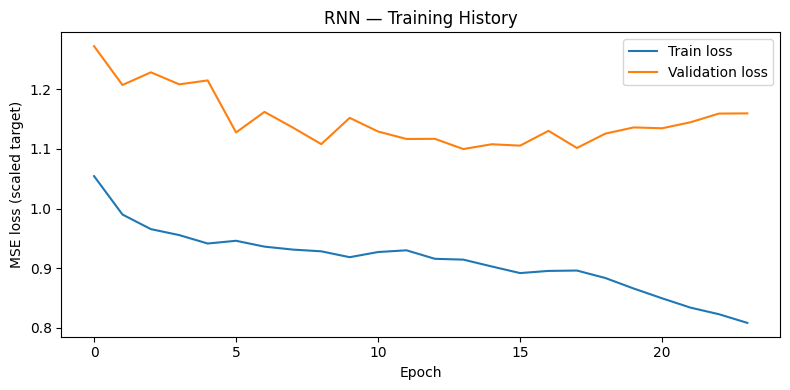

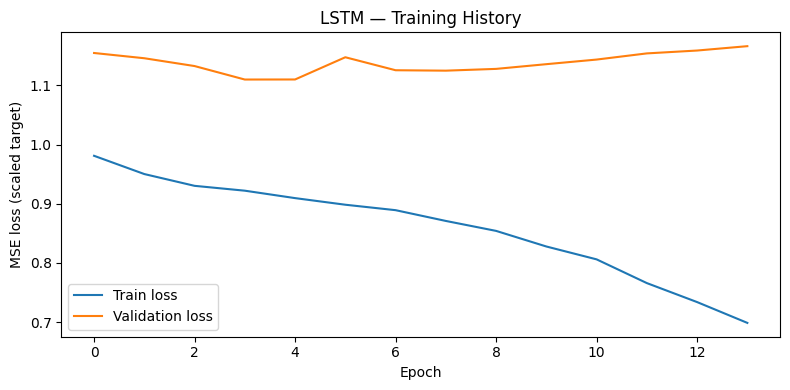

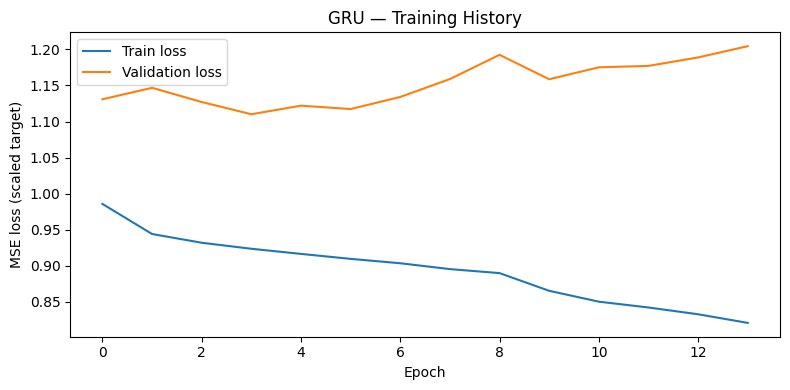

In [17]:
for name, history in histories.items():
    plt.figure(figsize=(8, 4))
    plt.plot(history.history["loss"], label="Train loss")
    plt.plot(history.history["val_loss"], label="Validation loss")
    plt.title(f"{name} — Training History")
    plt.xlabel("Epoch")
    plt.ylabel("MSE loss (scaled target)")
    plt.legend()
    plt.tight_layout()
    plt.show()


## 15. ارزیابی نهایی روی Test در واحد واقعی PM10

Test set تا پایان آموزش دست‌نخورده باقی می‌ماند.  
پیش‌بینی‌ها ابتدا به مقیاس واقعی `µg/m³` برگردانده می‌شوند و سپس معیارها محاسبه می‌شوند.


In [18]:
def smape(y_true, y_pred, eps=1e-8):
    denominator = np.abs(y_true) + np.abs(y_pred)
    return 100.0 * np.mean(2.0 * np.abs(y_pred - y_true) / np.maximum(denominator, eps))


def regression_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
        "sMAPE_percent": smape(y_true, y_pred)
    }


predictions_real = {}
metrics_rows = []

# Persistence baseline
baseline_metrics = regression_metrics(y_test_real, persistence_test)
metrics_rows.append({
    "Model": "Persistence",
    **baseline_metrics,
    "Parameters": 0,
    "Training_seconds": 0.0
})

# Neural models
for name, model in models.items():
    pred_scaled = model.predict(X_test, verbose=0).reshape(-1, 1)
    pred_real = target_scaler.inverse_transform(pred_scaled).ravel()

    # Air-pollution concentration cannot be negative physically.
    # We keep raw predictions for metrics by default; optional clipping can be compared separately.
    predictions_real[name] = pred_real

    m = regression_metrics(y_test_real, pred_real)

    metrics_rows.append({
        "Model": name,
        **m,
        "Parameters": model.count_params(),
        "Training_seconds": training_times[name]
    })

comparison = pd.DataFrame(metrics_rows).sort_values("RMSE").reset_index(drop=True)
display(comparison.round({
    "MAE": 3,
    "RMSE": 3,
    "R2": 4,
    "sMAPE_percent": 3,
    "Training_seconds": 1
}))

,Model,MAE,RMSE,R2,sMAPE_percent,Parameters,Training_seconds
0,LSTM,75.119,106.019,0.0714,68.884,138689,483.5
1,RNN,75.784,106.756,0.0584,69.451,35489,326.8
2,GRU,75.406,107.187,0.0508,69.556,104961,501.2
3,Persistence,102.644,141.957,-0.6649,88.940,0,0.0


## 16. نمودار مقایسه‌ی پیش‌بینی‌ها

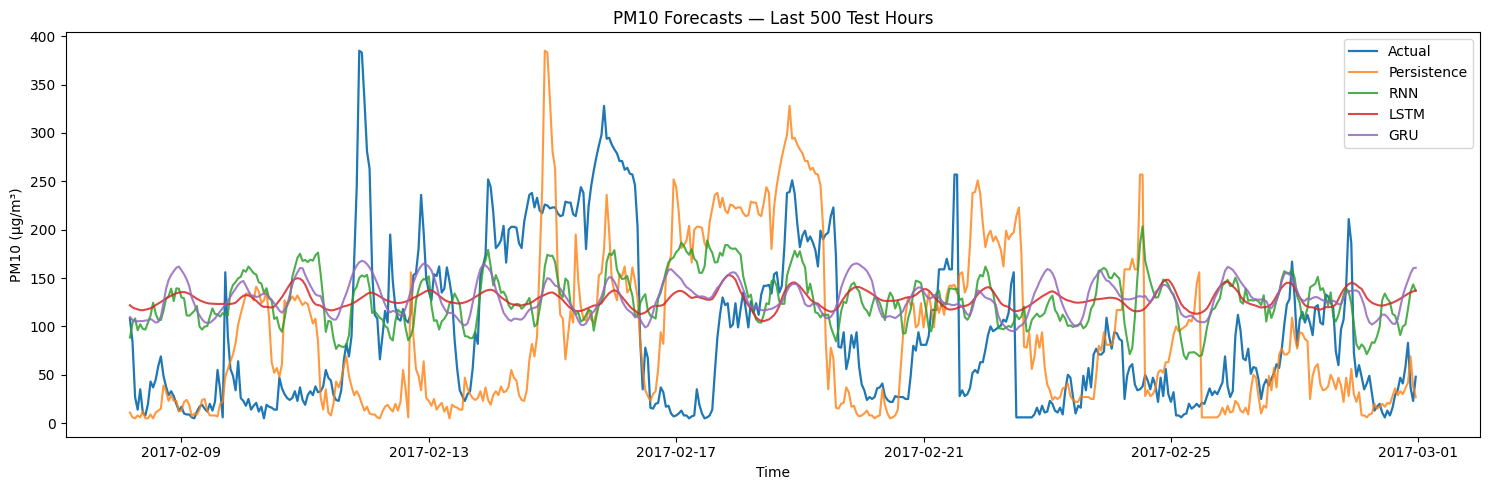

In [19]:
N_PLOT = min(500, len(y_test_real))
sl = slice(-N_PLOT, None)

plt.figure(figsize=(15, 5))
plt.plot(time_test[sl], y_test_real[sl], label="Actual", linewidth=1.6)
plt.plot(time_test[sl], persistence_test[sl], label="Persistence", alpha=0.8)

for name in ["RNN", "LSTM", "GRU"]:
    plt.plot(time_test[sl], predictions_real[name][sl], label=name, alpha=0.85)

plt.title(f"PM10 Forecasts — Last {N_PLOT} Test Hours")
plt.xlabel("Time")
plt.ylabel("PM10 (µg/m³)")
plt.legend()
plt.tight_layout()
plt.show()

## 17. جدول مقادیر واقعی و پیش‌بینی‌شده

In [20]:
results = pd.DataFrame({
    "datetime": time_test,
    "actual_PM10": y_test_real,
    "persistence": persistence_test,
    "RNN": predictions_real["RNN"],
    "LSTM": predictions_real["LSTM"],
    "GRU": predictions_real["GRU"]
})

display(results.head(20))

,datetime,actual_PM10,persistence,RNN,LSTM,GRU
0,2016-07-24 20:00:00,93.000000,55.999999,83.670792,104.236954,74.787888
1,2016-07-24 21:00:00,83.000000,83.999999,87.493050,100.488831,75.098404
2,2016-07-24 22:00:00,53.000000,100.000000,100.897789,94.893433,75.469299
3,2016-07-24 23:00:00,107.000000,77.000000,109.451675,86.214508,73.841553
4,2016-07-25 00:00:00,107.000000,89.000000,127.024818,79.054222,71.272400
5,2016-07-25 01:00:00,93.000000,73.000001,91.383583,73.602638,67.211678
6,2016-07-25 02:00:00,128.000000,83.999999,83.420891,69.716377,64.513145
7,2016-07-25 03:00:00,93.000000,80.999999,95.498390,67.597641,64.111198
8,2016-07-25 04:00:00,56.999996,95.000000,99.542496,66.867645,65.009926
9,2016-07-25 05:00:00,56.000000,68.000000,88.393402,66.762566,65.944473


## 18. تحلیل خطا

Best neural model by RMSE: LSTM


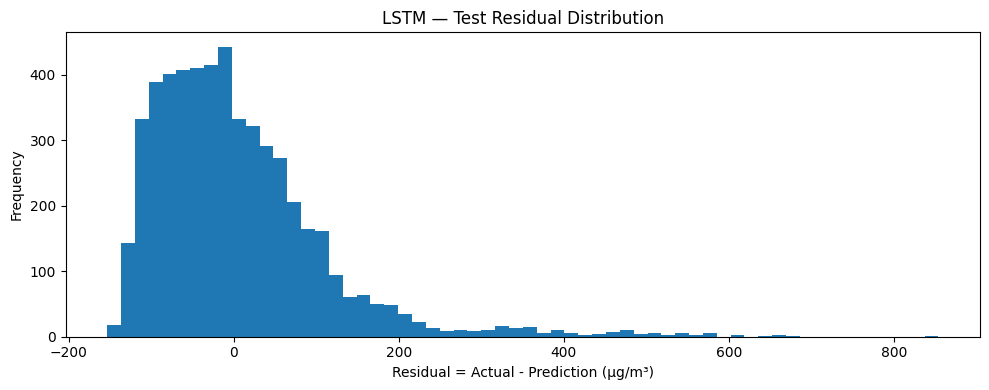

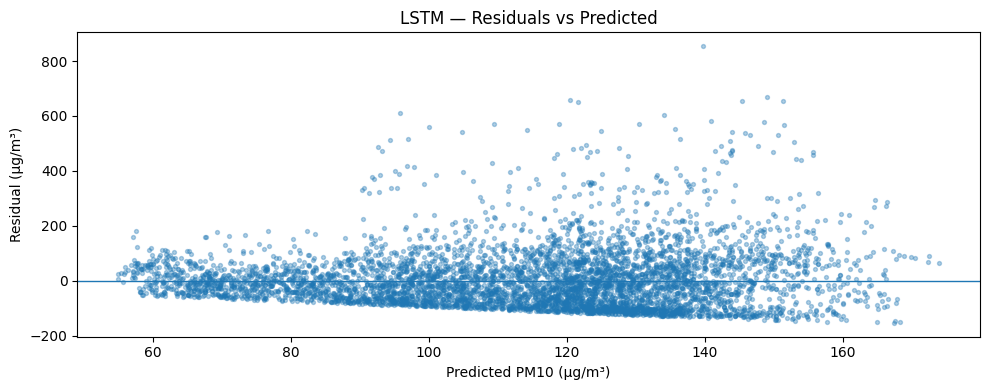

In [21]:
best_neural_name = (
    comparison[comparison["Model"].isin(["RNN", "LSTM", "GRU"])]
    .sort_values("RMSE")
    .iloc[0]["Model"]
)

best_pred = predictions_real[best_neural_name]
residuals = y_test_real - best_pred

print("Best neural model by RMSE:", best_neural_name)

plt.figure(figsize=(10, 4))
plt.hist(residuals, bins=60)
plt.title(f"{best_neural_name} — Test Residual Distribution")
plt.xlabel("Residual = Actual - Prediction (µg/m³)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 4))
plt.scatter(best_pred, residuals, s=8, alpha=0.35)
plt.axhline(0, linewidth=1)
plt.title(f"{best_neural_name} — Residuals vs Predicted")
plt.xlabel("Predicted PM10 (µg/m³)")
plt.ylabel("Residual (µg/m³)")
plt.tight_layout()
plt.show()


## 19. بررسی عملکرد در ساعات آلودگی شدید

میانگین خطا به‌تنهایی ممکن است عملکرد مدل در اوج‌های آلودگی را پنهان کند.  
در این بخش خطا برای نمونه‌هایی که PM10 واقعی بالاتر از صدک 90 Test است نیز جداگانه گزارش می‌شود.


In [22]:
high_threshold = np.quantile(y_test_real, 0.90)
high_mask = y_test_real >= high_threshold

peak_rows = []
for name, pred in [("Persistence", persistence_test)] + [(n, predictions_real[n]) for n in ["RNN", "LSTM", "GRU"]]:
    m = regression_metrics(y_test_real[high_mask], pred[high_mask])
    peak_rows.append({
        "Model": name,
        "Peak_threshold_PM10": high_threshold,
        "Peak_samples": int(high_mask.sum()),
        **m
    })

peak_comparison = pd.DataFrame(peak_rows).sort_values("RMSE")
display(peak_comparison.round(3))

,Model,Peak_threshold_PM10,Peak_samples,MAE,RMSE,R2,sMAPE_percent
1,RNN,246.0,535,231.531,263.278,-3.395,89.805
0,Persistence,246.0,535,230.329,264.343,-3.431,101.694
2,LSTM,246.0,535,232.032,264.540,-3.437,88.936
3,GRU,246.0,535,237.541,269.388,-3.602,92.772



## 20. ذخیره‌ی نتایج و مدل‌ها

خروجی‌ها شامل:

- هر سه مدل در فرمت `.keras`
- scalerهای ورودی و هدف
- جدول معیارهای کل Test
- جدول معیارهای اوج آلودگی
- پیش‌بینی‌های ساعتی Test
- فایل پیکربندی آزمایش


In [23]:
OUTPUT_DIR = Path("outputs_gucheng_pm10_72h_ahead")
OUTPUT_DIR.mkdir(exist_ok=True)

for name, model in models.items():
    model.save(OUTPUT_DIR / f"{name.lower()}_pm10.keras")

joblib.dump(feature_scaler, OUTPUT_DIR / "feature_scaler.joblib")
joblib.dump(target_scaler, OUTPUT_DIR / "target_scaler.joblib")

comparison.to_csv(OUTPUT_DIR / "test_metrics.csv", index=False)
peak_comparison.to_csv(OUTPUT_DIR / "peak_test_metrics.csv", index=False)
results.to_csv(OUTPUT_DIR / "test_predictions.csv", index=False)

config = {
    "target": TARGET,
    "features": FEATURES,
    "lookback_hours": LOOKBACK,
    "forecast_horizon_hours": HORIZON,
    "train_ratio": TRAIN_RATIO,
    "validation_ratio": VAL_RATIO,
    "test_ratio": TEST_RATIO,
    "epochs_max": EPOCHS,
    "batch_size": BATCH_SIZE,
    "learning_rate": LEARNING_RATE,
    "dropout": DROPOUT,
    "early_stopping_patience": PATIENCE,
    "seed": SEED
}

with open(OUTPUT_DIR / "experiment_config.json", "w", encoding="utf-8") as f:
    json.dump(config, f, ensure_ascii=False, indent=2)

print("Saved artifacts to:", OUTPUT_DIR.resolve())

Saved artifacts to: /content/outputs_gucheng_pm10_72h_ahead



## 21. آزمایش حساسیت به طول پنجره (مرحله‌ی بعدی پیشنهادی)

پس از تثبیت pipeline پایه، بهتر است آزمایش جداگانه‌ای با:

- 24 ساعت
- 48 ساعت
- 72 ساعت
- 168 ساعت

انجام شود.  
برای مقایسه‌ی علمی باید **تمام تنظیمات دیگر ثابت بمانند** و فقط `LOOKBACK` تغییر کند.

در فاز بعدی می‌توان مدل برتر این نوت‌بوک را با مدل‌های کلاسیک مانند Random Forest، XGBoost و SVR نیز روی همان split و همان horizon مقایسه کرد.



## یادداشت روش‌شناختی برای گزارش/پایان‌نامه

این آزمایش به‌صورت کنترل‌شده طراحی شده است: هر سه شبکه‌ی بازگشتی ورودی، پنجره‌ی زمانی، افق پیش‌بینی، تقسیم داده، preprocessing، optimizer و معیارهای یکسان دارند. بنابراین اختلاف عملکرد آن‌ها عمدتاً به تفاوت ساختاری واحدهای بازگشتی مربوط می‌شود.

با این حال، یکسان‌بودن تعداد واحدها به معنی یکسان‌بودن تعداد پارامترها نیست؛ LSTM و GRU به دلیل وجود سازوکارهای دروازه‌ای پارامترهای بیشتری نسبت به SimpleRNN دارند. به همین دلیل تعداد پارامترها نیز در جدول نهایی گزارش می‌شود.
